# Klasifikasi Citra Real vs AI-Generated dengan EfficientNet-B0
**Dataset:** CIFAKE + GenImage (subset) + AI vs Human-Generated Images
**Model:** EfficientNet-B0 (Transfer Learning + Fine-Tuning)
**Framework:** PyTorch

**Versi ini disesuaikan untuk dijalankan di Kaggle Notebooks** (GPU accelerator + dataset ditambahkan lewat panel "Add Data", bukan Google Drive/Colab upload).

Notebook ini disusun ulang dengan alur yang lebih rapi:
1. Setup & Konfigurasi
2. Download & Ekstrak Dataset
3. Persiapan Data (Transform, Dataset, DataLoader)
4. Definisi Model
5. Fungsi Training & Evaluasi (dipakai ulang untuk semua tahap)
6. Tahap 1: Training Head (Backbone dibekukan)
7. Tahap 2: Fine-Tuning (Seluruh layer dilatih)
8. Kurva Loss & Akurasi (Training vs Validasi)
9. Evaluasi Akhir pada Data Uji (Confusion Matrix, Classification Report, ROC-AUC)
10. Simpan & Unduh Model


## 1. Setup & Konfigurasi
Semua *import* dan pengaturan global (seed, device, hyperparameter) dikumpulkan di satu tempat agar mudah dilacak dan diubah.

In [3]:
import os
import time
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc

# --- Reproducibility ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# --- Device ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Perangkat yang digunakan: {device}")
if device.type == "cpu":
    print("PERINGATAN: GPU tidak terdeteksi. Training akan jauh lebih lambat. "
          "Di Kaggle: buka panel kanan 'Settings' > 'Accelerator' > pilih GPU T4 x2 atau P100, "
          "lalu restart session.")

# --- Penyimpanan (Kaggle) ---
# Di Kaggle, /kaggle/working/ adalah satu-satunya folder yang bisa ditulis dan bersifat
# persisten selama sesi notebook berjalan. Saat kamu menekan "Save Version" (commit),
# seluruh isi /kaggle/working/ akan disimpan sebagai Output notebook dan bisa diunduh
# kapan saja lewat tab "Output" -- jadi TIDAK perlu mount Google Drive seperti di Colab.
#
# Catatan sesi: Kaggle GPU session dibatasi (umumnya 12 jam berjalan / minggu kuota GPU
# terbatas). Kalau sesi berhenti di tengah training, checkpoint resume di bawah tetap
# akan tersimpan di /kaggle/working selama session belum benar-benar berakhir/di-reset;
# untuk keamanan ekstra, commit notebook secara berkala agar checkpoint ikut tersimpan
# sebagai Output permanen.
MODEL_DIR = "/kaggle/working/model"
os.makedirs(MODEL_DIR, exist_ok=True)

# --- Hyperparameter (kumpulkan di sini agar mudah di-tuning) ---
CONFIG = {
    # Path CIFAKE: sesuaikan dengan slug dataset yang kamu tambahkan lewat "+ Add Data"
    # (birdy654/cifake-real-and-ai-generated-synthetic-images). Jalankan sel inspeksi
    # struktur folder (2.2) kalau path di bawah tidak cocok.
    "train_dir": "/kaggle/input/cifake-real-and-ai-generated-synthetic-images/train",
    "test_dir": "/kaggle/input/cifake-real-and-ai-generated-synthetic-images/test",
    "img_size": 224,
    "batch_size": 32,
    "val_split": 0.2,
    "num_workers": 2,

    # Tahap 1: training head (backbone dibekukan)
    "head_lr": 1e-3,
    "head_epochs": 5,

    # Tahap 2: fine-tuning (seluruh layer dilatih)
    # Epoch dinaikkan karena sekarang ada early stopping -> aman, tidak akan
    # menjalankan semua 15 epoch kalau modelnya sudah berhenti membaik.
    "finetune_lr": 1e-5,
    "finetune_epochs": 15,

    # Regularisasi & optimisasi
    "weight_decay": 1e-4,
    "early_stopping_patience": 4,   # stop kalau val_acc tidak membaik N epoch berturut-turut
    "scheduler_factor": 0.5,        # LR dikali faktor ini tiap kali plateau
    "scheduler_patience": 2,        # tunggu N epoch tanpa perbaikan sebelum turunkan LR

    "class_names": ["AI-Generated", "Real Image"],  # index 0, 1 (mengikuti ImageFolder)

    # Struktur penyimpanan model
    "model_dir": MODEL_DIR,
    "feature_best_path": os.path.join(MODEL_DIR, "efficientnet_b0_feature_best.pth"),
    "finetune_best_path": os.path.join(MODEL_DIR, "efficientnet_b0_finetune_best.pth"),
    "deploy_model_path": os.path.join(MODEL_DIR, "model_efficientnet_b0.pth"),  # nama yang dikenali app Flask VeriPixel
    "resume_head_path": os.path.join(MODEL_DIR, "resume_head.pth"),
    "resume_finetune_path": os.path.join(MODEL_DIR, "resume_finetune.pth"),
    "history_csv_path": os.path.join(MODEL_DIR, "training_history.csv"),
    "eval_metrics_csv_path": os.path.join(MODEL_DIR, "evaluation_metrics.csv"),
}

print("\nKonfigurasi:")
for k, v in CONFIG.items():
    print(f"  {k}: {v}")


Perangkat yang digunakan: cuda

Konfigurasi:
  train_dir: /kaggle/input/cifake-real-and-ai-generated-synthetic-images/train
  test_dir: /kaggle/input/cifake-real-and-ai-generated-synthetic-images/test
  img_size: 224
  batch_size: 32
  val_split: 0.2
  num_workers: 2
  head_lr: 0.001
  head_epochs: 5
  finetune_lr: 1e-05
  finetune_epochs: 15
  weight_decay: 0.0001
  early_stopping_patience: 4
  scheduler_factor: 0.5
  scheduler_patience: 2
  class_names: ['AI-Generated', 'Real Image']
  model_dir: /kaggle/working/model
  feature_best_path: /kaggle/working/model/efficientnet_b0_feature_best.pth
  finetune_best_path: /kaggle/working/model/efficientnet_b0_finetune_best.pth
  deploy_model_path: /kaggle/working/model/model_efficientnet_b0.pth
  resume_head_path: /kaggle/working/model/resume_head.pth
  resume_finetune_path: /kaggle/working/model/resume_finetune.pth
  history_csv_path: /kaggle/working/model/training_history.csv
  eval_metrics_csv_path: /kaggle/working/model/evaluation_metric

## 2. Menambahkan Dataset (Kaggle "Add Data")

Di Kaggle **tidak perlu** unggah `kaggle.json` atau menjalankan `kaggle datasets download` —
dataset publik cukup ditambahkan langsung lewat panel kanan notebook:

1. Klik **"+ Add Input"** / **"Add Data"** di panel kanan.
2. Cari dan tambahkan ketiga dataset berikut (satu per satu):
   - `birdy654/cifake-real-and-ai-generated-synthetic-images`
   - `yangsangtai/tiny-genimage`
   - `alessandrasala79/ai-vs-human-generated-dataset`
3. Setelah ditambahkan, dataset otomatis tersedia (read-only) di:
   - `/kaggle/input/cifake-real-and-ai-generated-synthetic-images/`
   - `/kaggle/input/tiny-genimage/`
   - `/kaggle/input/ai-vs-human-generated-dataset/`

Tidak ada proses download/unzip manual yang perlu dijalankan — sel di bawah hanya
memverifikasi bahwa ketiga dataset tersebut sudah ter-attach dengan benar.


In [9]:
import os
print(os.listdir("/kaggle/input/datasets"))

['alessandrasala79', 'yangsangtai', 'birdy654']


In [10]:
import os

for owner in os.listdir("/kaggle/input/datasets"):
    print("="*60)
    print("Owner:", owner)
    print(os.listdir(f"/kaggle/input/datasets/{owner}"))

Owner: alessandrasala79
['ai-vs-human-generated-dataset']
Owner: yangsangtai
['tiny-genimage']
Owner: birdy654
['cifake-real-and-ai-generated-synthetic-images']


In [11]:
from pathlib import Path

DATASET_ROOT = Path("/kaggle/input/datasets")

CIFAKE_ROOT = next(DATASET_ROOT.rglob("cifake-real-and-ai-generated-synthetic-images"))
GENIMAGE_ROOT = next(DATASET_ROOT.rglob("tiny-genimage"))
AI_HUMAN_ROOT = next(DATASET_ROOT.rglob("ai-vs-human-generated-dataset"))

print(CIFAKE_ROOT)
print(GENIMAGE_ROOT)
print(AI_HUMAN_ROOT)

/kaggle/input/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images
/kaggle/input/datasets/yangsangtai/tiny-genimage
/kaggle/input/datasets/alessandrasala79/ai-vs-human-generated-dataset


In [12]:
import os

# ============================
# Verifikasi Dataset CIFAKE
# ============================

assert CIFAKE_ROOT.is_dir(), (
    f"Dataset CIFAKE tidak ditemukan di {CIFAKE_ROOT}"
)

print("=" * 60)
print("Dataset CIFAKE berhasil ditemukan")
print("=" * 60)

print("Lokasi :", CIFAKE_ROOT)
print()

print("Isi folder:")
print(os.listdir(CIFAKE_ROOT))

Dataset CIFAKE berhasil ditemukan
Lokasi : /kaggle/input/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images

Isi folder:
['test', 'train']


In [13]:
# ============================
# Konfigurasi Path CIFAKE
# ============================

CONFIG["train_dir"] = str(CIFAKE_ROOT / "train")
CONFIG["test_dir"] = str(CIFAKE_ROOT / "test")

print("=" * 60)
print("CIFAKE Dataset")
print("=" * 60)

print("Train :", CONFIG["train_dir"])
print("Ada   :", os.path.isdir(CONFIG["train_dir"]))

print()

print("Test  :", CONFIG["test_dir"])
print("Ada   :", os.path.isdir(CONFIG["test_dir"]))

CIFAKE Dataset
Train : /kaggle/input/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/train
Ada   : True

Test  : /kaggle/input/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/test
Ada   : True


## 2.1 Dataset Tambahan: GenImage & AI vs Human-Generated Images
Selain CIFAKE, ditambahkan dua dataset publik agar model lebih general (tidak hanya mengenali pola Stable Diffusion v1.4 pada gambar gaya CIFAR-10):

- **GenImage (subset)** — `yangsangtai/tiny-genimage`, versi ringkas dari dataset GenImage (Zhu et al., 2023, NeurIPS) yang mencakup gambar dari beberapa generator AI (mis. Midjourney, Stable Diffusion, ADM, GLIDE, Wukong, VQDM, BigGAN) dengan konten mengikuti kelas ImageNet.
- **AI vs Human-Generated Images** — `alessandrasala79/ai-vs-human-generated-dataset`, dataset kompetisi Kaggle (Women in AI 2025) berisi foto asli dan hasil AI generatif yang lebih beragam kontennya dibanding CIFAKE.

> Catatan: dataset GenImage versi penuh berukuran ratusan GB, sehingga di sini dipakai subset (*tiny-genimage*) yang jauh lebih ringan dan lebih cocok dijalankan di lingkungan Kaggle (dan Colab).
> Kedua dataset ini sudah ditambahkan lewat panel "+ Add Data" pada sel Bagian 2 -- sel di bawah hanya memverifikasi keberadaannya, tidak melakukan download/unzip apapun.

In [14]:
import os

# ============================
# Verifikasi Dataset GenImage
# ============================

assert GENIMAGE_ROOT.is_dir(), (
    f"Dataset GenImage tidak ditemukan di {GENIMAGE_ROOT}"
)

print("=" * 60)
print("Dataset GenImage berhasil ditemukan")
print("=" * 60)

print("Lokasi :", GENIMAGE_ROOT)
print()

print("Isi folder:")
print(os.listdir(GENIMAGE_ROOT))

Dataset GenImage berhasil ditemukan
Lokasi : /kaggle/input/datasets/yangsangtai/tiny-genimage

Isi folder:
['imagenet_ai_0424_wukong', 'imagenet_glide', 'imagenet_ai_0419_biggan', 'imagenet_ai_0419_vqdm', 'imagenet_midjourney', 'imagenet_ai_0424_sdv5', 'imagenet_ai_0508_adm']


In [15]:
import os

# ============================
# Verifikasi Dataset AI vs Human
# ============================

assert AI_HUMAN_ROOT.is_dir(), (
    f"Dataset AI vs Human tidak ditemukan di {AI_HUMAN_ROOT}"
)

print("=" * 60)
print("Dataset AI vs Human berhasil ditemukan")
print("=" * 60)

print("Lokasi :", AI_HUMAN_ROOT)
print()

print("Isi folder:")
print(os.listdir(AI_HUMAN_ROOT))

Dataset AI vs Human berhasil ditemukan
Lokasi : /kaggle/input/datasets/alessandrasala79/ai-vs-human-generated-dataset

Isi folder:
['test_data_v2', 'train.csv', 'test.csv', 'train_data']


## 2.2 Inspeksi Struktur Folder (PENTING — jalankan sebelum lanjut ke 2.3)
Struktur folder tiap dataset Kaggle bisa sedikit berbeda dari waktu ke waktu. Jalankan sel di bawah ini dan **periksa hasilnya**, karena nama folder yang ditemukan di sini perlu dicocokkan secara manual dengan variabel `GENIMAGE_AI_DIRS`, `GENIMAGE_REAL_DIRS`, dan `AIVSHUMAN_ROOT` pada sel 2.3.

In [21]:
import os

def show_tree(path, max_depth=2, max_items=5):
    path = str(path)  # agar Path maupun string bisa digunakan

    if not os.path.isdir(path):
        print(f"Folder tidak ditemukan: {path}")
        return

    for root, dirs, files in os.walk(path):
        depth = root[len(path):].count(os.sep)

        if depth > max_depth:
            dirs[:] = []
            continue

        indent = "  " * depth
        print(f"{indent}{os.path.basename(root) or root}/ ({len(files)} file)")

        for f in sorted(files)[:max_items]:
            print(f"{indent}  - {f}")

print("=== Struktur GenImage ===")
show_tree(GENIMAGE_ROOT)

print("\n=== Struktur AI vs Human ===")
show_tree(AI_HUMAN_ROOT)

=== Struktur GenImage ===
tiny-genimage/ (0 file)
  imagenet_ai_0424_wukong/ (0 file)
    val/ (0 file)
    train/ (0 file)
  imagenet_glide/ (0 file)
    val/ (0 file)
    train/ (0 file)
  imagenet_ai_0419_biggan/ (0 file)
    val/ (0 file)
    train/ (0 file)
  imagenet_ai_0419_vqdm/ (0 file)
    val/ (0 file)
    train/ (0 file)
  imagenet_midjourney/ (0 file)
    val/ (0 file)
    train/ (0 file)
  imagenet_ai_0424_sdv5/ (0 file)
    val/ (0 file)
    train/ (0 file)
  imagenet_ai_0508_adm/ (0 file)
    val/ (0 file)
    train/ (0 file)

=== Struktur AI vs Human ===
ai-vs-human-generated-dataset/ (2 file)
  - test.csv
  - train.csv
  test_data_v2/ (5540 file)
    - 0016e1d72d404fe68074cc87cb30aa37.jpg
    - 002cbbdc87f0484db60ed0c261c53e7b.jpg
    - 0030624722ae447b98cd36e9c734fce4.jpg
    - 0065d47a13fc4608a55be23d02a0f523.jpg
    - 007b141831394b01bfe01fde0a250f6d.jpg
  train_data/ (79950 file)
    - 000295da5dca4af09d5593174e15bb09.jpg
    - 0002f7db7beb4bf5879a0cdb7f17209d.jpg

In [22]:
from pathlib import Path
import os

base = GENIMAGE_ROOT

for dataset in base.iterdir():
    if not dataset.is_dir():
        continue

    train_path = dataset / "train"

    print("=" * 50)
    print(dataset.name)

    if train_path.exists():
        for root, dirs, files in os.walk(str(train_path)):
            level = root.replace(str(train_path), "").count(os.sep)

            if level > 2:
                dirs[:] = []
                continue

            indent = "  " * level
            print(indent + os.path.basename(root) + "/")

            if files:
                print(indent + f"({len(files)} files)")
    else:
        print("Folder train tidak ditemukan.")

imagenet_ai_0424_wukong
train/
  nature/
  (2000 files)
  ai/
  (2000 files)
imagenet_glide
train/
  nature/
  (2000 files)
  ai/
  (2000 files)
imagenet_ai_0419_biggan
train/
  nature/
  (2000 files)
  ai/
  (2000 files)
imagenet_ai_0419_vqdm
train/
  nature/
  (2000 files)
  ai/
  (2000 files)
imagenet_midjourney
train/
  nature/
  (2000 files)
  ai/
  (2000 files)
imagenet_ai_0424_sdv5
train/
  nature/
  (2000 files)
  ai/
  (2000 files)
imagenet_ai_0508_adm
train/
  nature/
  (2000 files)
  ai/
  (2000 files)


## 2.3 Menggabungkan Semua Dataset menjadi Struktur Terpadu (REAL/FAKE)

**Alur baru (sesuai diagram):**

```
CIFAKE     ─┐
GenImage   ─┼──▶ Gabung semua jadi satu manifest ──▶ Sampling seimbang REAL & FAKE
AI vs Human─┘
```

Bedanya dengan versi sebelumnya:
- Semua gambar dari ketiga sumber didata dulu ke satu tabel (`manifest`) berisi
  `path`, `label`, `source`, dan `split` (train/test) — **bukan** ditautkan langsung
  per sumber dengan limit masing-masing seperti sebelumnya.
- Setelah digabung, baru dilakukan **sampling seimbang** dari kolam data campuran ini
  untuk data latih (target total bisa diatur lewat `TARGET_TRAIN_TOTAL`), sehingga
  campuran sumbernya lebih representatif ketimbang dibatasi kaku per sumber.
- Data uji (`test_combined`) **tidak** disampling — dipakai penuh apa adanya, supaya
  evaluasi akhir semaksimal mungkin mencerminkan performa nyata di berbagai sumber.
- Manifest final disimpan sebagai `train_manifest.csv` / `test_manifest.csv` di
  `model/` — berguna untuk lampiran skripsi (tabel komposisi dataset) dan supaya
  proses ini bisa ditelusuri ulang.
- Nama file symlink diberi prefix sumber (`cifake_`, `genimage_`, `aivh_`) sehingga
  nanti bisa dipakai untuk **evaluasi performa per dataset** di Bagian 9.

Ketiga dataset digabung menggunakan **symlink** (bukan menyalin file) agar hemat
ruang penyimpanan (`/kaggle/working` di Kaggle punya kuota terbatas, umumnya ~20GB, jadi symlink ke `/kaggle/input` jauh lebih hemat daripada menyalin file).

In [23]:
random.seed(SEED)

COMBINED_TRAIN_DIR = "/kaggle/working/train_combined"
COMBINED_TEST_DIR = "/kaggle/working/test_combined"
CLASSES = ["FAKE", "REAL"]

# Bersihkan folder gabungan sebelumnya supaya aman dijalankan berkali-kali
# (mis. setelah runtime reconnect) dan angkanya selalu akurat.
for split_dir in [COMBINED_TRAIN_DIR, COMBINED_TEST_DIR]:
    if os.path.isdir(split_dir):
        shutil.rmtree(split_dir)
    for cls in CLASSES:
        os.makedirs(os.path.join(split_dir, cls), exist_ok=True)


def list_images(folder):
    if not os.path.isdir(folder):
        return []
    return [
        os.path.join(folder, f) for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]


manifest_rows = []

# ==========================================================
# 1. CIFAKE -> sudah punya train/ dan test/ eksplisit
# ==========================================================
print("Mendata CIFAKE...")
for cls in CLASSES:
    for f in list_images(f"{CONFIG['train_dir']}/{cls}"):
        manifest_rows.append({"path": f, "label": cls, "source": "cifake", "split": "train"})
    for f in list_images(f"{CONFIG['test_dir']}/{cls}"):
        manifest_rows.append({"path": f, "label": cls, "source": "cifake", "split": "test"})

# ==========================================================
# 2. GenImage -> train/ untuk latih, val/ untuk uji
# ==========================================================
GENIMAGE_GENERATORS = [
    "imagenet_glide",
    "imagenet_ai_0508_adm",
    "imagenet_ai_0419_biggan",
    "imagenet_ai_0424_wukong",
    "imagenet_ai_0424_sdv5",
    "imagenet_midjourney",
    "imagenet_ai_0419_vqdm",
]

print("Mendata GenImage...")
for gen in tqdm(GENIMAGE_GENERATORS, desc="GenImage generators"):
    for split, subfolder in [("train", "train"), ("test", "val")]:
        for cls, folder_name in [("FAKE", "ai"), ("REAL", "nature")]:
            d = os.path.join(str(GENIMAGE_ROOT), gen, subfolder, folder_name)
            for f in list_images(d):
                manifest_rows.append({
                    "path": f,
                    "label": cls,
                    "source": "genimage",
                    "split": split,
                })

# ==========================================================
# 3. AI vs Human-Generated Images -> hanya train.csv yang berlabel,
#    displit 85/15 (stratified per label) jadi train/test.
#    PERBAIKAN: rel_path di CSV sudah mengandung prefix "train_data/",
#    jadi TIDAK di-join lagi dengan "train_data" (dulu jadi folder ganda).
# ==========================================================
AIVSHUMAN_TEST_FRACTION = 0.15

csv_path = os.path.join(str(AI_HUMAN_ROOT), "train.csv")

print("Mendata AI vs Human-Generated Images...")

if os.path.exists(csv_path):

    aivh_df = pd.read_csv(csv_path)

    file_col = "file_name" if "file_name" in aivh_df.columns else aivh_df.columns[0]
    label_col = "label" if "label" in aivh_df.columns else aivh_df.columns[-1]

    for lbl, group in aivh_df.groupby(label_col):

        shuffled = group.sample(frac=1.0, random_state=SEED)

        n_test = int(len(shuffled) * AIVSHUMAN_TEST_FRACTION)

        cls = "FAKE" if int(lbl) == 1 else "REAL"

        for i, (_, row) in enumerate(shuffled.iterrows()):

            split = "test" if i < n_test else "train"

            full_path = os.path.join(
                str(AI_HUMAN_ROOT),
                str(row[file_col])
            )

            manifest_rows.append({
                "path": full_path,
                "label": cls,
                "source": "aivh",
                "split": split,
            })

else:
    print(f"[SKIP] {csv_path} tidak ditemukan.")

# ==========================================================
# Gabungkan jadi satu manifest, buang entri yang file-nya tidak ada
# ==========================================================
manifest = pd.DataFrame(manifest_rows)
print(f"\nTotal entri manifest (sebelum verifikasi keberadaan file): {len(manifest)}")

exists_mask = [os.path.exists(p) for p in tqdm(manifest["path"], desc="Verifikasi file")]
manifest = manifest[exists_mask].reset_index(drop=True)
print(f"Total entri manifest (setelah verifikasi): {len(manifest)}")

print("\nKomposisi manifest per sumber, label, dan split:")
print(manifest.groupby(["source", "label", "split"]).size())

# ==========================================================
# Sampling: gabung semua -> ambil sejumlah target per kelas
# ==========================================================
TARGET_TRAIN_TOTAL = 150000  # turunkan (mis. 120000) kalau training masih terlalu lama
TARGET_TRAIN_PER_CLASS = TARGET_TRAIN_TOTAL // 2

train_pool = manifest[manifest["split"] == "train"]
test_pool = manifest[manifest["split"] == "test"]

train_sampled = []
for cls in CLASSES:
    pool_cls = train_pool[train_pool["label"] == cls]
    n = min(TARGET_TRAIN_PER_CLASS, len(pool_cls))
    if n < TARGET_TRAIN_PER_CLASS:
        print(f"[INFO] Data latih {cls} hanya tersedia {len(pool_cls)} "
              f"(< target {TARGET_TRAIN_PER_CLASS}), memakai semuanya.")
    train_sampled.append(pool_cls.sample(n=n, random_state=SEED))

train_final = pd.concat(train_sampled).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
test_final = test_pool.reset_index(drop=True)  # data uji dipakai penuh, tidak disampling

print(f"\nTotal data latih setelah sampling : {len(train_final)}")
print(f"Total data uji (dipakai penuh)     : {len(test_final)}")
print("\nKomposisi data LATIH per sumber & label:")
print(train_final.groupby(["source", "label"]).size().unstack(fill_value=0))
print("\nKomposisi data UJI per sumber & label:")
print(test_final.groupby(["source", "label"]).size().unstack(fill_value=0))

# ==========================================================
# Symlink ke struktur ImageFolder + simpan manifest ke CSV
# ==========================================================

def link_final(df_final, dst_root):
    linked_names = []
    for i, row in enumerate(tqdm(df_final.itertuples(), total=len(df_final), desc=f"Symlink -> {dst_root}")):
        ext = os.path.splitext(row.path)[1].lower()
        fname = f"{row.source}_{i}{ext}"
        dst = os.path.join(dst_root, row.label, fname)
        if not os.path.exists(dst):
            os.symlink(os.path.abspath(row.path), dst)
        linked_names.append(fname)
    return linked_names

train_final = train_final.copy()
test_final = test_final.copy()
train_final["linked_filename"] = link_final(train_final, COMBINED_TRAIN_DIR)
test_final["linked_filename"] = link_final(test_final, COMBINED_TEST_DIR)

os.makedirs(CONFIG["model_dir"], exist_ok=True)
train_manifest_path = os.path.join(CONFIG["model_dir"], "train_manifest.csv")
test_manifest_path = os.path.join(CONFIG["model_dir"], "test_manifest.csv")
train_final.to_csv(train_manifest_path, index=False)
test_final.to_csv(test_manifest_path, index=False)

print(f"\nManifest data latih disimpan ke: {train_manifest_path}")
print(f"Manifest data uji   disimpan ke: {test_manifest_path}")

print("\n========== RINGKASAN AKHIR (isi folder) ==========")
for cls in CLASSES:
    print(f"TRAIN {cls}: {len(os.listdir(f'{COMBINED_TRAIN_DIR}/{cls}'))}")
for cls in CLASSES:
    print(f"TEST  {cls}: {len(os.listdir(f'{COMBINED_TEST_DIR}/{cls}'))}")

CONFIG["train_dir"] = COMBINED_TRAIN_DIR
CONFIG["test_dir"] = COMBINED_TEST_DIR
print("\nCONFIG diperbarui:", CONFIG["train_dir"], "|", CONFIG["test_dir"])

Mendata CIFAKE...
Mendata GenImage...


GenImage generators:   0%|          | 0/7 [00:00<?, ?it/s]

Mendata AI vs Human-Generated Images...

Total entri manifest (sebelum verifikasi keberadaan file): 234950


Verifikasi file:   0%|          | 0/234950 [00:00<?, ?it/s]

Total entri manifest (setelah verifikasi): 234950

Komposisi manifest per sumber, label, dan split:
source    label  split
aivh      FAKE   test      5996
                 train    33979
          REAL   test      5996
                 train    33979
cifake    FAKE   test     10000
                 train    50000
          REAL   test     10000
                 train    50000
genimage  FAKE   test      3500
                 train    14000
          REAL   test      3500
                 train    14000
dtype: int64

Total data latih setelah sampling : 150000
Total data uji (dipakai penuh)     : 38992

Komposisi data LATIH per sumber & label:
label      FAKE   REAL
source                
aivh      26046  26046
cifake    38212  38212
genimage  10742  10742

Komposisi data UJI per sumber & label:
label      FAKE   REAL
source                
aivh       5996   5996
cifake    10000  10000
genimage   3500   3500


Symlink -> /kaggle/working/train_combined:   0%|          | 0/150000 [00:00<?, ?it/s]

Symlink -> /kaggle/working/test_combined:   0%|          | 0/38992 [00:00<?, ?it/s]


Manifest data latih disimpan ke: /kaggle/working/model/train_manifest.csv
Manifest data uji   disimpan ke: /kaggle/working/model/test_manifest.csv

========== RINGKASAN AKHIR (isi folder) ==========
TRAIN FAKE: 75000
TRAIN REAL: 75000
TEST  FAKE: 19496
TEST  REAL: 19496

CONFIG diperbarui: /kaggle/working/train_combined | /kaggle/working/test_combined


## 3. Persiapan Data
- **Augmentasi** hanya diterapkan pada data latih (`transform_train`), bukan pada data validasi/uji, agar evaluasi mencerminkan data asli.
- Split train/validasi menggunakan *generator* dengan seed tetap, sehingga hasilnya konsisten setiap kali notebook dijalankan ulang.

In [24]:
transform_train = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

transform_eval = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Dataset mentah dipakai dua kali dengan transform berbeda (train vs val)
# agar augmentasi tidak ikut diterapkan ke data validasi.
full_train_raw = datasets.ImageFolder(CONFIG["train_dir"])
print("Mapping kelas:", full_train_raw.class_to_idx)

n_total = len(full_train_raw)
n_val = int(CONFIG["val_split"] * n_total)
n_train = n_total - n_val

generator = torch.Generator().manual_seed(SEED)
train_indices, val_indices = random_split(
    range(n_total), [n_train, n_val], generator=generator
)

train_dataset = torch.utils.data.Subset(
    datasets.ImageFolder(CONFIG["train_dir"], transform=transform_train), train_indices.indices
)
val_dataset = torch.utils.data.Subset(
    datasets.ImageFolder(CONFIG["train_dir"], transform=transform_eval), val_indices.indices
)
test_dataset = datasets.ImageFolder(CONFIG["test_dir"], transform=transform_eval)

train_loader = DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True,
                           num_workers=CONFIG["num_workers"], pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                         num_workers=CONFIG["num_workers"], pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                          num_workers=CONFIG["num_workers"], pin_memory=True)

print(f"Total Data Latih   : {len(train_dataset)}")
print(f"Total Data Validasi: {len(val_dataset)}")
print(f"Total Data Uji     : {len(test_dataset)}")

# Komposisi sumber data pada train/val (berdasarkan prefix nama file symlink,
# mis. "cifake_123.jpg" -> "cifake") -- berguna untuk tabel di laporan skripsi.
def source_counts(indices):
    sources = [os.path.basename(full_train_raw.samples[i][0]).split("_")[0] for i in indices]
    return pd.Series(sources).value_counts()

print("\nKomposisi sumber pada data LATIH:")
print(source_counts(train_indices.indices))
print("\nKomposisi sumber pada data VALIDASI:")
print(source_counts(val_indices.indices))

Mapping kelas: {'FAKE': 0, 'REAL': 1}
Total Data Latih   : 120000
Total Data Validasi: 30000
Total Data Uji     : 38992

Komposisi sumber pada data LATIH:
cifake      61170
aivh        41607
genimage    17223
Name: count, dtype: int64

Komposisi sumber pada data VALIDASI:
cifake      15254
aivh        10485
genimage     4261
Name: count, dtype: int64


## 4. Definisi Model
Menggunakan EfficientNet-B0 pra-latih (ImageNet). Layer klasifikasi terakhir diganti menjadi satu neuron output untuk klasifikasi biner.

Catatan: lapisan `Sigmoid` **tidak** dipasang langsung di dalam model. Sebagai gantinya kita memakai `BCEWithLogitsLoss`, yang menggabungkan sigmoid + binary cross-entropy dalam satu operasi yang lebih stabil secara numerik. Sigmoid hanya diterapkan secara terpisah saat menghitung akurasi/probabilitas.

In [25]:
model = models.efficientnet_b0(
    weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1
)

# Freeze backbone
for param in model.parameters():
    param.requires_grad = False

num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, 1)

model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("EfficientNet-B0 berhasil dimuat.")
print(f"Total parameter      : {total_params:,}")
print(f"Trainable parameter  : {trainable_params:,}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 167MB/s]


EfficientNet-B0 berhasil dimuat.
Total parameter      : 4,008,829
Trainable parameter  : 1,281


## 5. Fungsi Training & Evaluasi

Fungsi training di bawah ini sudah dilengkapi:

- **Progress bar** (tqdm) per batch, menampilkan loss & akurasi berjalan.
- **Weight decay** pada optimizer (regularisasi L2, lewat `CONFIG["weight_decay"]`).
- **Learning rate scheduler** (`ReduceLROnPlateau`) — LR otomatis diturunkan kalau
  akurasi validasi berhenti membaik selama `scheduler_patience` epoch.
- **Early stopping** — training dihentikan otomatis kalau akurasi validasi tidak
  membaik selama `early_stopping_patience` epoch, supaya tidak buang waktu/kuota
  sesi GPU melatih epoch yang percuma.
- **Checkpoint resume** — tiap epoch, seluruh state (bobot model, optimizer,
  scheduler, epoch ke berapa, akurasi terbaik sejauh ini) disimpan ke file resume.
  Kalau sesi Kaggle terputus/reset di tengah jalan, tinggal jalankan ulang sel yang
  sama — training otomatis lanjut dari epoch terakhir yang sempat tersimpan,
  **tidak perlu mengulang dari awal**.
- **History ke CSV** — `training_history.csv` diperbarui setiap epoch (bukan cuma
  di akhir), jadi kalau training terhenti, riwayat sampai epoch terakhir tetap aman.

In [26]:
def run_epoch(model, loader, criterion, optimizer=None, desc="Epoch"):
    """Menjalankan satu epoch dengan progress bar. Jika optimizer diberikan -> mode
    training, jika None -> mode evaluasi (tanpa update bobot)."""
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    running_loss, correct, total = 0.0, 0, 0
    context = torch.enable_grad() if is_train else torch.no_grad()

    pbar = tqdm(loader, desc=desc, leave=False)
    with context:
        for inputs, labels in pbar:
            inputs = inputs.to(device)
            labels = labels.float().unsqueeze(1).to(device)

            if is_train:
                optimizer.zero_grad()

            logits = model(inputs)
            loss = criterion(logits, labels)

            if is_train:
                loss.backward()
                optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            preds = (torch.sigmoid(logits) > 0.5).float()
            correct += (preds == labels).sum().item()
            total += labels.size(0)

            pbar.set_postfix(loss=f"{running_loss/total:.4f}", acc=f"{100*correct/total:.2f}%")

    epoch_loss = running_loss / total
    epoch_acc = 100 * correct / total
    return epoch_loss, epoch_acc


def save_resume_checkpoint(path, model, optimizer, scheduler, epoch, best_val_acc, patience_counter):
    """Menyimpan seluruh state training (bukan cuma bobot model) supaya training
    bisa dilanjutkan persis dari titik terakhir kalau runtime terputus."""
    torch.save({
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict() if scheduler is not None else None,
        "best_val_acc": best_val_acc,
        "patience_counter": patience_counter,
    }, path)


def save_history_csv(history, path):
    pd.DataFrame(history).to_csv(path, index=False)


def train_model(model, train_loader, val_loader, criterion, optimizer, epochs, history,
                 phase_name="", best_checkpoint_path=None, resume_checkpoint_path=None,
                 scheduler=None, best_val_acc=0.0, patience=4, start_epoch=0, patience_counter=0):
    """Melatih model selama `epochs`, dengan early stopping, LR scheduler, progress
    bar, checkpoint resume, dan logging history ke CSV setiap epoch."""
    print(f"--- Memulai {phase_name} (mulai dari epoch {start_epoch + 1}/{epochs}) ---")

    for epoch in range(start_epoch, epochs):
        t0 = time.time()
        train_loss, train_acc = run_epoch(
            model, train_loader, criterion, optimizer,
            desc=f"{phase_name} [{epoch+1}/{epochs}] train",
        )
        val_loss, val_acc = run_epoch(
            model, val_loader, criterion, optimizer=None,
            desc=f"{phase_name} [{epoch+1}/{epochs}] val",
        )
        elapsed = time.time() - t0
        current_lr = optimizer.param_groups[0]["lr"]

        history["phase"].append(phase_name)
        history["epoch"].append(epoch + 1)
        history["lr"].append(current_lr)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"[{phase_name}] Epoch [{epoch+1}/{epochs}] "
              f"Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | "
              f"Val Loss: {val_loss:.4f} Acc: {val_acc:.2f}% | "
              f"LR: {current_lr:.2e} | Waktu: {elapsed:.1f}s")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            patience_counter = 0
            if best_checkpoint_path:
                torch.save(model.state_dict(), best_checkpoint_path)
                print(f"  -> Model terbaik baru disimpan ke {best_checkpoint_path} (Val Acc: {val_acc:.2f}%)")
        else:
            patience_counter += 1
            print(f"  -> Val acc belum membaik ({patience_counter}/{patience})")

        if scheduler is not None:
            if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_acc)
            else:
                scheduler.step()

        if CONFIG.get("history_csv_path"):
            save_history_csv(history, CONFIG["history_csv_path"])

        if resume_checkpoint_path:
            save_resume_checkpoint(resume_checkpoint_path, model, optimizer, scheduler,
                                    epoch + 1, best_val_acc, patience_counter)

        if patience_counter >= patience:
            print(f"  -> Early stopping dipicu setelah {patience} epoch tanpa peningkatan.")
            break

    # Fase ini tuntas (early stop maupun mencapai batas epoch) -> hapus resume
    # checkpoint fase ini, supaya run berikutnya tahu fase ini sudah selesai.
    if resume_checkpoint_path and os.path.exists(resume_checkpoint_path):
        os.remove(resume_checkpoint_path)

    return best_val_acc, patience_counter


criterion = nn.BCEWithLogitsLoss()

if os.path.exists(CONFIG["history_csv_path"]):
    history = pd.read_csv(CONFIG["history_csv_path"]).to_dict(orient="list")
    print(f"History training sebelumnya ditemukan ({len(history['epoch'])} epoch tercatat) -> akan dilanjutkan.")
else:
    history = {"phase": [], "epoch": [], "lr": [], "train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    print("Belum ada history training sebelumnya -> mulai dari kosong.")

Belum ada history training sebelumnya -> mulai dari kosong.


In [27]:
# Ringkasan komposisi dataset gabungan untuk data LATIH (dibaca dari manifest CSV
# yang disimpan di sel 2.3) -- berguna untuk tabel deskripsi dataset di BAB IV.
train_manifest_check = pd.read_csv(os.path.join(CONFIG["model_dir"], "train_manifest.csv"))
print("Komposisi data LATIH per sumber & label:")
print(train_manifest_check.groupby(["source", "label"]).size().unstack(fill_value=0))

Komposisi data LATIH per sumber & label:
label      FAKE   REAL
source                
aivh      26046  26046
cifake    38212  38212
genimage  10742  10742


In [28]:
# Ringkasan komposisi dataset gabungan untuk data UJI
test_manifest_check = pd.read_csv(os.path.join(CONFIG["model_dir"], "test_manifest.csv"))
print("Komposisi data UJI per sumber & label:")
print(test_manifest_check.groupby(["source", "label"]).size().unstack(fill_value=0))

Komposisi data UJI per sumber & label:
label      FAKE   REAL
source                
aivh       5996   5996
cifake    10000  10000
genimage   3500   3500


## 6. Tahap 1: Training Head (Backbone Dibekukan)

Sel ini otomatis mendeteksi status sebelumnya:
- Kalau `efficientnet_b0_feature_best.pth` sudah ada **dan** tidak ada resume
  checkpoint tertunda -> tahap ini dianggap **sudah selesai**, langsung dilewati
  (bobot terbaik dimuat, tidak training ulang dari nol).
- Kalau ada resume checkpoint tertunda -> training **dilanjutkan** dari epoch
  terakhir yang tersimpan (aman dari runtime yang terputus).
- Kalau belum ada keduanya -> training dimulai dari awal.

In [29]:
if os.path.exists(CONFIG["feature_best_path"]) and not os.path.exists(CONFIG["resume_head_path"]):
    print("Tahap 1 (Training Head) sudah pernah selesai sebelumnya -> melewati training ulang.")
    print(f"Memuat bobot terbaik dari: {CONFIG['feature_best_path']}")
    model.load_state_dict(
        torch.load(
            CONFIG["feature_best_path"],
            map_location=device,
            weights_only=True,
        )
    )
    best_val_acc_head = max(
        (v for p, v in zip(history["phase"], history["val_acc"]) if p == "Training Head (Tahap 1)"),
        default=0.0,
    )
else:
    optimizer = optim.Adam(
        model.classifier[1].parameters(),
        lr=CONFIG["head_lr"], weight_decay=CONFIG["weight_decay"],
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=CONFIG["scheduler_factor"], patience=CONFIG["scheduler_patience"],
    )

    start_epoch, patience_counter, best_val_acc_head = 0, 0, 0.0
    if os.path.exists(CONFIG["resume_head_path"]):
        print("Resume checkpoint Tahap 1 ditemukan, melanjutkan training...")
        ckpt = torch.load(
            CONFIG["resume_head_path"],
            map_location=device,
            weights_only=False,
        )
        model.load_state_dict(ckpt["model_state"])
        optimizer.load_state_dict(ckpt["optimizer_state"])
        if ckpt.get("scheduler_state"):
            scheduler.load_state_dict(ckpt["scheduler_state"])
        start_epoch = ckpt["epoch"]
        best_val_acc_head = ckpt["best_val_acc"]
        patience_counter = ckpt["patience_counter"]

    best_val_acc_head, _ = train_model(
        model, train_loader, val_loader, criterion, optimizer,
        epochs=CONFIG["head_epochs"], history=history,
        phase_name="Training Head (Tahap 1)",
        best_checkpoint_path=CONFIG["feature_best_path"],
        resume_checkpoint_path=CONFIG["resume_head_path"],
        scheduler=scheduler, best_val_acc=best_val_acc_head,
        patience=CONFIG["early_stopping_patience"],
        start_epoch=start_epoch, patience_counter=patience_counter,
    )

print(f"\nTahap 1 selesai. Akurasi validasi terbaik (head): {best_val_acc_head:.2f}%")

--- Memulai Training Head (Tahap 1) (mulai dari epoch 1/5) ---


Training Head (Tahap 1) [1/5] train:   0%|          | 0/3750 [00:00<?, ?it/s]

Training Head (Tahap 1) [1/5] val:   0%|          | 0/938 [00:00<?, ?it/s]

[Training Head (Tahap 1)] Epoch [1/5] Train Loss: 0.4753 Acc: 77.00% | Val Loss: 0.4530 Acc: 78.45% | LR: 1.00e-03 | Waktu: 1005.3s
  -> Model terbaik baru disimpan ke /kaggle/working/model/efficientnet_b0_feature_best.pth (Val Acc: 78.45%)


Training Head (Tahap 1) [2/5] train:   0%|          | 0/3750 [00:00<?, ?it/s]

...

Training Head (Tahap 1) [4/5] val:   0%|          | 0/938 [00:00<?, ?it/s]

[Training Head (Tahap 1)] Epoch [4/5] Train Loss: 0.4585 Acc: 78.28% | Val Loss: 0.4432 Acc: 79.02% | LR: 1.00e-03 | Waktu: 540.4s
  -> Val acc belum membaik (1/4)


Training Head (Tahap 1) [5/5] train:   0%|          | 0/3750 [00:00<?, ?it/s]

Training Head (Tahap 1) [5/5] val:   0%|          | 0/938 [00:00<?, ?it/s]

[Training Head (Tahap 1)] Epoch [5/5] Train Loss: 0.4629 Acc: 77.90% | Val Loss: 0.4333 Acc: 79.84% | LR: 1.00e-03 | Waktu: 541.6s
  -> Model terbaik baru disimpan ke /kaggle/working/model/efficientnet_b0_feature_best.pth (Val Acc: 79.84%)

Tahap 1 selesai. Akurasi validasi terbaik (head): 79.84%


## 7. Tahap 2: Fine-Tuning (Seluruh Layer Dilatih)

Sama seperti Tahap 1, sel ini mendeteksi status otomatis (selesai / resume /
mulai baru). Kalau baru mulai (bukan resume), bobot yang dipakai sebagai titik
awal adalah **bobot terbaik Tahap 1** (`efficientnet_b0_feature_best.pth`), bukan
sekadar bobot di epoch terakhir Tahap 1 -- supaya fine-tuning dimulai dari kondisi
model yang paling optimal.

In [30]:
if os.path.exists(CONFIG["finetune_best_path"]) and not os.path.exists(CONFIG["resume_finetune_path"]):
    print("Tahap 2 (Fine-Tuning) sudah pernah selesai sebelumnya -> melewati training ulang.")
    print(f"Memuat bobot terbaik dari: {CONFIG['finetune_best_path']}")
    for param in model.parameters():
        param.requires_grad = True
    model.load_state_dict(
        torch.load(
            CONFIG["finetune_best_path"],
            map_location=device,
            weights_only=True,
        )
    )
    best_val_acc = max(history["val_acc"], default=0.0)
else:
    if not os.path.exists(CONFIG["resume_finetune_path"]):
        # Baru mulai Tahap 2 -> mulai dari bobot TERBAIK hasil Tahap 1 (bukan epoch terakhir)
        print(f"Memuat bobot terbaik Tahap 1 dari: {CONFIG['feature_best_path']}")
        model.load_state_dict(
            torch.load(
                CONFIG["feature_best_path"],
                map_location=device,
                weights_only=True,
            )
        )

    for param in model.parameters():
        param.requires_grad = True

    optimizer = optim.Adam(
        model.parameters(),
        lr=CONFIG["finetune_lr"], weight_decay=CONFIG["weight_decay"],
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=CONFIG["scheduler_factor"], patience=CONFIG["scheduler_patience"],
    )

    start_epoch, patience_counter, best_val_acc = 0, 0, 0.0
    if os.path.exists(CONFIG["resume_finetune_path"]):
        print("Resume checkpoint Tahap 2 ditemukan, melanjutkan training...")
        ckpt = torch.load(
            CONFIG["resume_finetune_path"],
            map_location=device,
            weights_only=False,
        )
        model.load_state_dict(ckpt["model_state"])
        optimizer.load_state_dict(ckpt["optimizer_state"])
        if ckpt.get("scheduler_state"):
            scheduler.load_state_dict(ckpt["scheduler_state"])
        start_epoch = ckpt["epoch"]
        best_val_acc = ckpt["best_val_acc"]
        patience_counter = ckpt["patience_counter"]

    best_val_acc, _ = train_model(
        model, train_loader, val_loader, criterion, optimizer,
        epochs=CONFIG["finetune_epochs"], history=history,
        phase_name="Fine-Tuning (Tahap 2)",
        best_checkpoint_path=CONFIG["finetune_best_path"],
        resume_checkpoint_path=CONFIG["resume_finetune_path"],
        scheduler=scheduler, best_val_acc=best_val_acc,
        patience=CONFIG["early_stopping_patience"],
        start_epoch=start_epoch, patience_counter=patience_counter,
    )

print(f"\nFine-Tuning selesai. Akurasi validasi terbaik: {best_val_acc:.2f}%")

Memuat bobot terbaik Tahap 1 dari: /kaggle/working/model/efficientnet_b0_feature_best.pth
--- Memulai Fine-Tuning (Tahap 2) (mulai dari epoch 1/15) ---


Fine-Tuning (Tahap 2) [1/15] train:   0%|          | 0/3750 [00:00<?, ?it/s]

Fine-Tuning (Tahap 2) [1/15] val:   0%|          | 0/938 [00:00<?, ?it/s]

[Fine-Tuning (Tahap 2)] Epoch [1/15] Train Loss: 0.3286 Acc: 85.33% | Val Loss: 0.2338 Acc: 90.02% | LR: 1.00e-05 | Waktu: 768.3s
  -> Model terbaik baru disimpan ke /kaggle/working/model/efficientnet_b0_finetune_best.pth (Val Acc: 90.02%)


Fine-Tuning (Tahap 2) [2/15] train:   0%|          | 0/3750 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ab0562a1da0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^Exception ignored in: ^<function _MultiProcessingDataLoaderIter.__del__ at 0x7ab0562a1da0>^^
^Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
^^    ^self._shutdown_workers()
^  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
^^    ^if w.is_alive():^
^^  ^^ ^  ^^  ^

[Fine-Tuning (Tahap 2)] Epoch [14/15] Train Loss: 0.0738 Acc: 97.15% | Val Loss: 0.0913 Acc: 96.43% | LR: 1.00e-05 | Waktu: 756.2s
  -> Model terbaik baru disimpan ke /kaggle/working/model/efficientnet_b0_finetune_best.pth (Val Acc: 96.43%)


Fine-Tuning (Tahap 2) [15/15] train:   0%|          | 0/3750 [00:00<?, ?it/s]

Fine-Tuning (Tahap 2) [15/15] val:   0%|          | 0/938 [00:00<?, ?it/s]

[Fine-Tuning (Tahap 2)] Epoch [15/15] Train Loss: 0.0693 Acc: 97.33% | Val Loss: 0.0900 Acc: 96.53% | LR: 1.00e-05 | Waktu: 1330.4s
  -> Model terbaik baru disimpan ke /kaggle/working/model/efficientnet_b0_finetune_best.pth (Val Acc: 96.53%)

Fine-Tuning selesai. Akurasi validasi terbaik: 96.53%


## 8. Kurva Loss & Akurasi (Training vs Validasi)

History selalu dibaca ulang dari `training_history.csv` (bukan cuma variabel
`history` di memori), supaya kurva tetap akurat & lengkap walaupun sebagian
tahap sempat di-resume atau dilewati di sesi yang berbeda-beda.

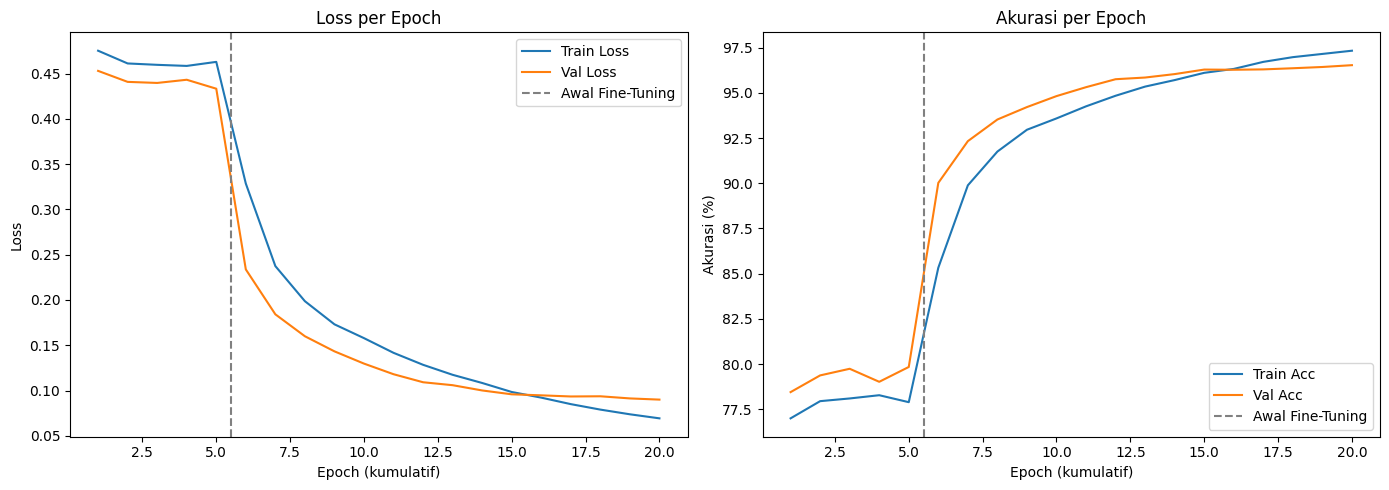

Total epoch tercatat: 20 (Tahap 1: 5, Tahap 2: 15)
History lengkap tersimpan di: /kaggle/working/model/training_history.csv


In [32]:
history_df = (
    pd.read_csv(CONFIG["history_csv_path"])
    if os.path.exists(CONFIG["history_csv_path"])
    else pd.DataFrame(history)
)

epochs_range = range(1, len(history_df) + 1)
n_head_epochs = int((history_df["phase"] == "Training Head (Tahap 1)").sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, history_df["train_loss"], label="Train Loss")
axes[0].plot(epochs_range, history_df["val_loss"], label="Val Loss")
if n_head_epochs:
    axes[0].axvline(n_head_epochs + 0.5, color="gray", linestyle="--", label="Awal Fine-Tuning")
axes[0].set_title("Loss per Epoch")
axes[0].set_xlabel("Epoch (kumulatif)")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(epochs_range, history_df["train_acc"], label="Train Acc")
axes[1].plot(epochs_range, history_df["val_acc"], label="Val Acc")
if n_head_epochs:
    axes[1].axvline(n_head_epochs + 0.5, color="gray", linestyle="--", label="Awal Fine-Tuning")
axes[1].set_title("Akurasi per Epoch")
axes[1].set_xlabel("Epoch (kumulatif)")
axes[1].set_ylabel("Akurasi (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Total epoch tercatat: {len(history_df)} "
      f"(Tahap 1: {n_head_epochs}, Tahap 2: {len(history_df) - n_head_epochs})")
print(f"History lengkap tersimpan di: {CONFIG['history_csv_path']}")

## 9. Evaluasi Akhir pada Data Uji

Evaluasi memuat bobot **terbaik hasil Fine-Tuning** (`efficientnet_b0_finetune_best.pth`).
Selain akurasi keseluruhan, sel-sel berikut juga menghitung confusion matrix,
classification report, ROC-AUC -- dan di Bagian 9.1, **metrik per sumber dataset**
(CIFAKE / GenImage / AI vs Human) secara terpisah.

In [33]:
print(f"Memuat bobot terbaik hasil Fine-Tuning dari: {CONFIG['finetune_best_path']}")
model.load_state_dict(
    torch.load(
        CONFIG["finetune_best_path"],
        map_location=device,
        weights_only=True,
    )
)
model.eval()

all_labels, all_preds, all_probs = [], [], []

print(f"--- Memulai Evaluasi pada Data Uji ({len(test_dataset)} Gambar) ---")
with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc="Evaluasi Data Uji"):
        inputs = inputs.to(device)
        logits = model(inputs)
        probs = torch.sigmoid(logits).cpu().numpy()
        preds = (probs > 0.5).astype(float)

        all_labels.extend(labels.numpy())
        all_preds.extend(preds)
        all_probs.extend(probs)

all_labels = np.array(all_labels)
all_preds = np.array(all_preds).flatten()
all_probs = np.array(all_probs).flatten()

test_acc = 100 * (all_preds == all_labels).mean()
print(f"Akurasi Akhir pada Data Uji (gabungan semua sumber): {test_acc:.2f}%")

# Sumber tiap sampel uji (untuk evaluasi per-dataset di Bagian 9.1), diambil dari
# prefix nama file symlink yang dibuat di sel 2.3 (mis. "cifake_123.jpg" -> "cifake")
test_sources = np.array([
    os.path.basename(path).split("_")[0] for path, _ in test_dataset.samples
])

Memuat bobot terbaik hasil Fine-Tuning dari: /kaggle/working/model/efficientnet_b0_finetune_best.pth
--- Memulai Evaluasi pada Data Uji (38992 Gambar) ---


Evaluasi Data Uji:   0%|          | 0/1219 [00:00<?, ?it/s]

Akurasi Akhir pada Data Uji (gabungan semua sumber): 96.18%


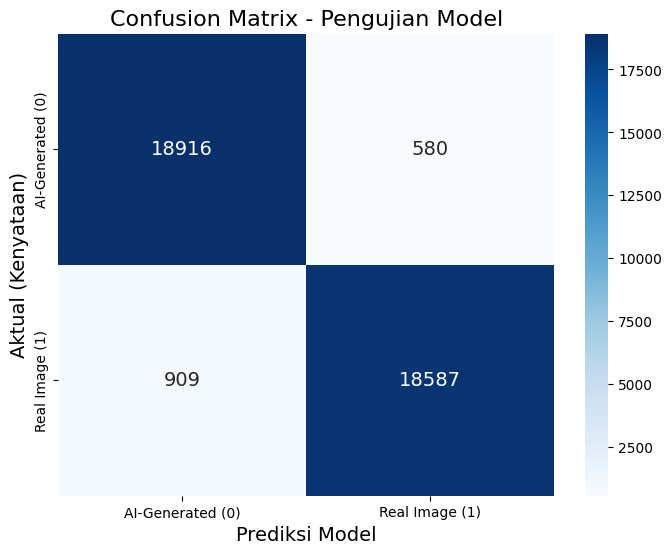

In [34]:
# ==========================================
# 1. CONFUSION MATRIX
# ==========================================
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[f"{n} ({i})" for i, n in enumerate(CONFIG["class_names"])],
            yticklabels=[f"{n} ({i})" for i, n in enumerate(CONFIG["class_names"])],
            annot_kws={"size": 14})
plt.title("Confusion Matrix - Pengujian Model", fontsize=16)
plt.xlabel("Prediksi Model", fontsize=14)
plt.ylabel("Aktual (Kenyataan)", fontsize=14)
plt.show()


In [35]:
# ==========================================
# 2. LAPORAN METRIK EVALUASI
# ==========================================
print("\n" + "=" * 50)
print("LAPORAN METRIK KLASIFIKASI")
print("=" * 50)
report = classification_report(all_labels, all_preds, target_names=CONFIG["class_names"])
print(report)



LAPORAN METRIK KLASIFIKASI
              precision    recall  f1-score   support

AI-Generated       0.95      0.97      0.96     19496
  Real Image       0.97      0.95      0.96     19496

    accuracy                           0.96     38992
   macro avg       0.96      0.96      0.96     38992
weighted avg       0.96      0.96      0.96     38992



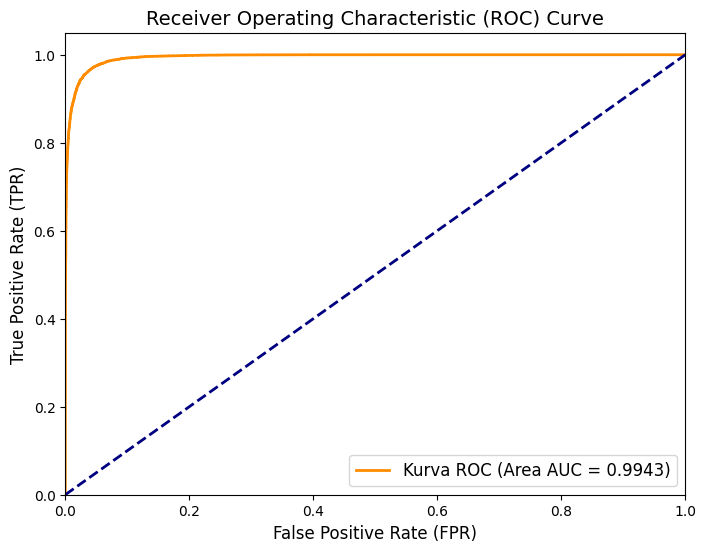

In [36]:
# ==========================================
# 3. KURVA ROC-AUC
# ==========================================
fpr, tpr, thresholds = roc_curve(all_labels, all_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"Kurva ROC (Area AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (FPR)", fontsize=12)
plt.ylabel("True Positive Rate (TPR)", fontsize=12)
plt.title("Receiver Operating Characteristic (ROC) Curve", fontsize=14)
plt.legend(loc="lower right", fontsize=12)
plt.show()


## 9.1 Evaluasi Performa per Dataset (CIFAKE, GenImage, AI vs Human)

Selain evaluasi pada gabungan seluruh data uji, performa model dipecah per sumber
dataset asal. Ini penting untuk melihat apakah model benar-benar general (bekerja
baik di semua jenis data/generator), atau ternyata hanya unggul di satu sumber
tertentu saja -- bagian ini akan jadi nilai tambah signifikan untuk pembahasan
hasil penelitian di BAB IV. Hasilnya juga disimpan ke `evaluation_metrics.csv`.

In [37]:
def compute_metrics(labels, preds, probs, name):
    n = len(labels)
    if n == 0:
        print(f"[SKIP] Tidak ada sampel untuk {name}.")
        return None

    acc = 100 * (preds == labels).mean()
    report = classification_report(
        labels, preds, target_names=CONFIG["class_names"],
        output_dict=True, zero_division=0,
    )
    try:
        fpr, tpr, _ = roc_curve(labels, probs)
        roc_auc = auc(fpr, tpr)
    except ValueError:
        roc_auc = float("nan")

    ai_key, real_key = CONFIG["class_names"]
    row = {
        "dataset": name,
        "n_samples": n,
        "accuracy_%": round(acc, 2),
        "precision_ai_%": round(report[ai_key]["precision"] * 100, 2),
        "recall_ai_%": round(report[ai_key]["recall"] * 100, 2),
        "f1_ai_%": round(report[ai_key]["f1-score"] * 100, 2),
        "precision_real_%": round(report[real_key]["precision"] * 100, 2),
        "recall_real_%": round(report[real_key]["recall"] * 100, 2),
        "f1_real_%": round(report[real_key]["f1-score"] * 100, 2),
        "roc_auc": round(roc_auc, 4) if roc_auc == roc_auc else None,
    }

    print(f"\n--- {name} (n={n}) ---")
    print(f"Akurasi: {acc:.2f}% | ROC-AUC: {roc_auc:.4f}")
    print(classification_report(labels, preds, target_names=CONFIG["class_names"], zero_division=0))
    return row


eval_rows = [compute_metrics(all_labels, all_preds, all_probs, "Gabungan (Semua Dataset)")]

for label_name, source_key in [
    ("CIFAKE", "cifake"),
    ("GenImage", "genimage"),
    ("AI vs Human-Generated", "aivh"),
]:
    mask = test_sources == source_key
    eval_rows.append(compute_metrics(all_labels[mask], all_preds[mask], all_probs[mask], label_name))

eval_df = pd.DataFrame([r for r in eval_rows if r is not None])
eval_df.to_csv(CONFIG["eval_metrics_csv_path"], index=False)

print(f"\nMetrik evaluasi per dataset disimpan ke: {CONFIG['eval_metrics_csv_path']}")
eval_df


--- Gabungan (Semua Dataset) (n=38992) ---
Akurasi: 96.18% | ROC-AUC: 0.9943
              precision    recall  f1-score   support

AI-Generated       0.95      0.97      0.96     19496
  Real Image       0.97      0.95      0.96     19496

    accuracy                           0.96     38992
   macro avg       0.96      0.96      0.96     38992
weighted avg       0.96      0.96      0.96     38992


--- CIFAKE (n=20000) ---
Akurasi: 97.73% | ROC-AUC: 0.9984
              precision    recall  f1-score   support

AI-Generated       0.96      0.99      0.98     10000
  Real Image       0.99      0.96      0.98     10000

    accuracy                           0.98     20000
   macro avg       0.98      0.98      0.98     20000
weighted avg       0.98      0.98      0.98     20000


--- GenImage (n=7000) ---
Akurasi: 88.46% | ROC-AUC: 0.9527
              precision    recall  f1-score   support

AI-Generated       0.89      0.88      0.88      3500
  Real Image       0.88      0.89     

,dataset,n_samples,accuracy_%,precision_ai_%,recall_ai_%,f1_ai_%,precision_real_%,recall_real_%,f1_real_%,roc_auc
0,Gabungan (Semua Dataset),38992,96.18,95.41,97.03,96.21,96.97,95.34,96.15,0.9943
1,CIFAKE,20000,97.74,96.40,99.17,97.77,99.15,96.30,97.70,0.9984
2,GenImage,7000,88.46,88.81,88.00,88.40,88.11,88.91,88.51,0.9527
3,AI vs Human-Generated,11992,98.10,97.51,98.72,98.11,98.70,97.48,98.09,0.9986


## 10. Simpan Model Final

Struktur penyimpanan (di `/kaggle/working/model/`):

```
model/
├── efficientnet_b0_feature_best.pth    # bobot terbaik Tahap 1 (training head)
├── efficientnet_b0_finetune_best.pth   # bobot terbaik Tahap 2 (fine-tuning) -- MODEL FINAL
├── model_efficientnet_b0.pth           # salinan finetune_best, nama yang dikenali app Flask VeriPixel
├── train_manifest.csv                  # rincian sumber tiap gambar data latih
├── test_manifest.csv                   # rincian sumber tiap gambar data uji
├── training_history.csv                # loss/akurasi/LR tiap epoch (Tahap 1 & 2)
└── evaluation_metrics.csv              # metrik evaluasi keseluruhan + per dataset
```

Semua file di atas sudah berada di `/kaggle/working/`, jadi begitu kamu menekan
**"Save Version"** (commit notebook), seluruh isi folder ini otomatis ikut tersimpan
sebagai **Output** notebook dan bisa diunduh langsung lewat tab **"Output"** di sisi
kanan (atau tab Output pada halaman versi notebook) -- tidak perlu Google Drive.


In [38]:
print("Berkas checkpoint yang tersimpan selama training:")
print(f"  - Best (Training Head) : {CONFIG['feature_best_path']}")
print(f"  - Best (Fine-Tuning)   : {CONFIG['finetune_best_path']}")

# Salin bobot fine-tuning terbaik menjadi nama yang dikenali langsung oleh
# aplikasi Flask VeriPixel (inference.py mencari 'model/model_efficientnet_b0.pth')
shutil.copy(CONFIG["finetune_best_path"], CONFIG["deploy_model_path"])
print(f"\nModel siap-deploy disalin ke : {CONFIG['deploy_model_path']}")
print(f"History training              : {CONFIG['history_csv_path']}")
print(f"Metrik evaluasi                : {CONFIG['eval_metrics_csv_path']}")

print(f"\nSemua berkas di atas berada di /kaggle/working/model -- akan otomatis")
print("tersimpan sebagai Output notebook setelah kamu klik 'Save Version' (commit).")


Berkas checkpoint yang tersimpan selama training:
  - Best (Training Head) : /kaggle/working/model/efficientnet_b0_feature_best.pth
  - Best (Fine-Tuning)   : /kaggle/working/model/efficientnet_b0_finetune_best.pth

Model siap-deploy disalin ke : /kaggle/working/model/model_efficientnet_b0.pth
History training              : /kaggle/working/model/training_history.csv
Metrik evaluasi                : /kaggle/working/model/evaluation_metrics.csv

Semua berkas di atas berada di /kaggle/working/model -- akan otomatis
tersimpan sebagai Output notebook setelah kamu klik 'Save Version' (commit).


In [39]:
# Di Kaggle tidak ada google.colab.files.download(). Cara mengunduh hasil training:
# 1. Klik "Save Version" (commit) di kanan atas notebook.
# 2. Setelah commit selesai, buka tab "Output" pada halaman versi notebook tersebut --
#    seluruh isi /kaggle/working/ (termasuk folder model/) akan terlihat di sana dan
#    bisa diunduh satu per satu atau sekaligus (tombol "Download All").
#
# Sebagai alternatif yang lebih ringkas, sel ini membuat satu file .zip berisi
# model final + CSV history & metrik evaluasi, supaya lebih mudah diunduh dari tab Output.
import zipfile

zip_path = "/kaggle/working/veripixel_model_bundle.zip"
files_to_zip = [
    CONFIG["deploy_model_path"],
    CONFIG["finetune_best_path"],
    CONFIG["feature_best_path"],
    CONFIG["history_csv_path"],
    CONFIG["eval_metrics_csv_path"],
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in files_to_zip:
        if os.path.exists(path):
            zf.write(path, arcname=os.path.basename(path))
        else:
            print(f"[SKIP] File tidak ditemukan: {path}")

print(f"\nBundle siap diunduh: {zip_path}")
print("Jalankan 'Save Version' lalu unduh file ini dari tab Output.")



Bundle siap diunduh: /kaggle/working/veripixel_model_bundle.zip
Jalankan 'Save Version' lalu unduh file ini dari tab Output.


In [42]:
import os

print(os.listdir("/kaggle/working"))

['train_combined', 'test_combined', '.virtual_documents', 'veripixel_model_bundle.zip', 'model']
